In [7]:
import pymc as pm
import numpy as np
import pytensor
import pytensor.tensor as pt
from models import base_model
from priors.alpha_prior import get_d2g_alpha
from priors.transition_prior import TransitionPrior


class Model3(base_model.Model):
    def __init__(self, data=None, coords=None):
        super().__init__(data=data, coords=coords)
        self.alpha = np.ones(self.V)
        self.M = 8

    @staticmethod
    def step_fn(t, state_tm1, transition_p, end_t):
        V = transition_p.shape[0]
        idx = pt.clip(state_tm1, 0, V - 1)

        state_t = pm.Categorical.dist(p=transition_p[idx])

        end_state = pm.DiracDelta.dist(-1, shape=state_t.shape)
        state_t = pt.where(t >= end_t, end_state, state_t)

        return state_t, pm.pytensorf.collect_default_updates([state_t])

    @staticmethod
    def scan_dist(init_state, transition_p, end_t, size):
        states, _ = pytensor.scan(
            fn=Model3.step_fn,
            sequences=[pt.arange(end_t.max())],
            outputs_info=[init_state],
            non_sequences=[transition_p, end_t],
            strict=True,
        )
        return states

    def _calc_conditional_logp(self, x_tm1, x_t, mask, A, m_val):
        m_b = pt.alloc(m_val, x_tm1.shape[0], m_val.shape[0])
        step_logps = pt.log(A[m_b, x_tm1, x_t]) # A[mode, from, to]
        return pt.sum(step_logps * mask)

    def build_model(self, x_0_obs=None, x_t_obs=None, lengths_obs=None, m_obs=None, **kwargs):
        with pm.Model() as model:
            nu = pm.Dirichlet("nu", a=np.ones(self.M))

            W_base = pm.Normal("W_base", mu=0, sigma=1.0, shape=(self.V, self.V))
            W_mode_offset = pm.Normal("W_mode_offset", mu=0, sigma=0.5, shape=(self.M, self.V, self.V))
            
            W_total = W_base + W_mode_offset
            A = pm.Deterministic("A", pm.math.softmax(W_total, axis=-1))
            
            pi = pm.Dirichlet("pi", a=self.alpha)

            if x_t_obs is not None:
                pm.Categorical("x_0", p=pi, observed=x_0_obs)

                x_0_reshaped = pt.shape_padleft(x_0_obs)
                x_full = pt.concatenate([x_0_reshaped, x_t_obs], axis=0)
                x_tm1 = x_full[:-1]
                x_t = x_full[1:]

                t_idx = pt.arange(x_t_obs.shape[0])
                mask = t_idx[:, None] < lengths_obs[None, :]

                pm.Categorical("m", p=nu, observed=m_obs)
                seq_ll = self._calc_conditional_logp(x_tm1, x_t, mask, A, m_obs)
                pm.Potential("conditional_ll", seq_ll)

            else:
                if m_obs is not None:
                    m = pm.Categorical("m", p=nu, observed=m_obs)
                else:
                    m = pm.Categorical("m", p=nu)

                transition_p = pm.Deterministic("A_m", A[m])
                x_0 = pm.Categorical("x_0", p=pi)
                length = pm.Poisson("length", self.mean_seq_len)

                pm.CustomDist(
                    "x_t+1",
                    x_0,
                    transition_p,
                    length,
                    dist=Model3.scan_dist,
                )

        self.model = model
        return model

In [15]:
m3 = Model3()
m3.alpha = get_d2g_alpha(m3.V)
m3.build_model()


/var/folders/64/v2j39fj147b5_y9gs8478v2m0000gn/T/ipykernel_82300/2952085346.py:30: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  states, _ = pytensor.scan(
/var/folders/64/v2j39fj147b5_y9gs8478v2m0000gn/T/ipykernel_82300/2952085346.py:30: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  states, _ = pytensor.scan(


           nu ~ Dirichlet(<constant>)
       W_base ~ Normal(0, 1)
W_mode_offset ~ Normal(0, 0.5)
           pi ~ Dirichlet(<constant>)
            m ~ Categorical(nu)
          x_0 ~ Categorical(pi)
       length ~ Poisson(40)
        x_t+1 ~ CustomDist_x_t+1(x_0, A_m, length)
            A ~ Deterministic(f(W_mode_offset, W_base))
          A_m ~ Deterministic(f(m, W_mode_offset, W_base))

In [9]:
import importlib
import analysis.compare_dist_of_intv as compare
import pandas as pd
importlib.reload(compare)

GS = pd.read_csv("data/data_gs.csv")
GS = GS[["volpiano_pitches", "modus"]].dropna()
data = GS[GS["modus"].isin(["1","2","3","4","5","6","7","8"])]
#data["modus"] = data["modus"].apply(lambda x: int(x)-1) # Index 0
data

,volpiano_pitches,modus
0,gghjhghhggkklhgfghhghkjkhkkkklhhghgkkhjggffhkj...,8
1,hhhghgeghghjhghghjhghkjkjkjhhjkjkjhjjhghjklkkj...,2
3,hgfghgegffedfghgfghgegfffehghgghhhghghgefgffdf...,4
4,cdddfddcddfgffffddefdcdacffefdddfddcddfgfffgff...,2
5,gjhhhhkhkkhgjghjhhhkhklmkjhhgjhgggfhghhfghkkhg...,2
...,...,...
154,kklkhhhggggjhhgggfghhghfffhghfhghghkkkkkgfgghg...,5
155,ddeddffffghfddfefefddddeddfefgdedccefffdgfghgg...,2
156,ggfffdeccdffghkhhgghfgkjjjjhgghghjkghffhkkkjkh...,8
157,dffgfffffghhfgfedgffgfffhfghkklmnkkhklkkkkhkhj...,5


In [10]:
raw_sequences = data["volpiano_pitches"].tolist()
    
raw_m = None
if "modus" in data.columns and data["modus"].notna().any():
    raw_m = data["modus"].astype(int).tolist()

trace = m3.fit_from_raw(
        raw_sequences=raw_sequences,
        raw_m=raw_m,
        draws=3000,
        tune=2000,
        backup="samples/model3_logit_test_4.nc"
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, W_base, W_mode_offset, pi]


Output()

Sampling 4 chains for 2_000 tune and 3_000 draw iterations (8_000 + 12_000 draws total) took 6315 seconds.
There were 2741 divergences after tuning. Increase `target_accept` or reparameterize.


In [11]:
import arviz as az
az.summary(trace)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
"W_base[0, 0]",-0.146,0.938,-1.863,1.647,0.008,0.009,13335.0,7892.0,1.0
"W_base[0, 1]",-0.149,0.938,-1.976,1.546,0.009,0.010,11886.0,7197.0,1.0
"W_base[0, 2]",2.418,0.764,1.045,3.915,0.007,0.008,11374.0,7444.0,1.0
"W_base[0, 3]",-0.127,0.953,-1.964,1.622,0.008,0.010,12636.0,6663.0,1.0
"W_base[0, 4]",-0.144,0.948,-1.973,1.598,0.008,0.011,14269.0,6977.0,1.0
...,...,...,...,...,...,...,...,...,...
"A[7, 17, 13]",0.054,0.065,0.000,0.166,0.001,0.002,11783.0,7561.0,1.0
"A[7, 17, 14]",0.056,0.070,0.000,0.179,0.001,0.002,11542.0,6643.0,1.0
"A[7, 17, 15]",0.057,0.071,0.001,0.182,0.001,0.002,11469.0,6934.0,1.0
"A[7, 17, 16]",0.056,0.069,0.000,0.172,0.001,0.002,11929.0,7190.0,1.0


/Users/timeipert/PycharmProjects/generative_medieval_music_model/venvnew/lib/python3.11/site-packages/arviz/plots/distcomparisonplot.py:161: UserWarning: rcParams['plot.max_subplots'] (40) is smaller than the number of subplots to plot (11068), generating only 40 plots
  warnings.warn(


array([[<Axes: >, <Axes: xlabel='W_base\n0, 0'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 1'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 2'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 3'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 4'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 5'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 6'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 7'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 8'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 9'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 10'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 11'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 12'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 13'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 14'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 15'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 16'>],
       [<Axes: >, <Axes: xlabel='W_base\n0, 17'>],
       [<Axes: >, <Axes: xlabel='W_base\n1, 0'>],
       [<Axes: >, <Axes: xlabel='W_base\n1



In [12]:
az.plot_dist_comparison(trace)

{'baseline_logits': <Figure size 1440x1224 with 2 Axes>,
 'mode_offsets': <Figure size 11520x1224 with 16 Axes>,
 'transition_matrices': <Figure size 11520x1224 with 16 Axes>,
 'mode_probabilities': <Figure size 800x400 with 1 Axes>}

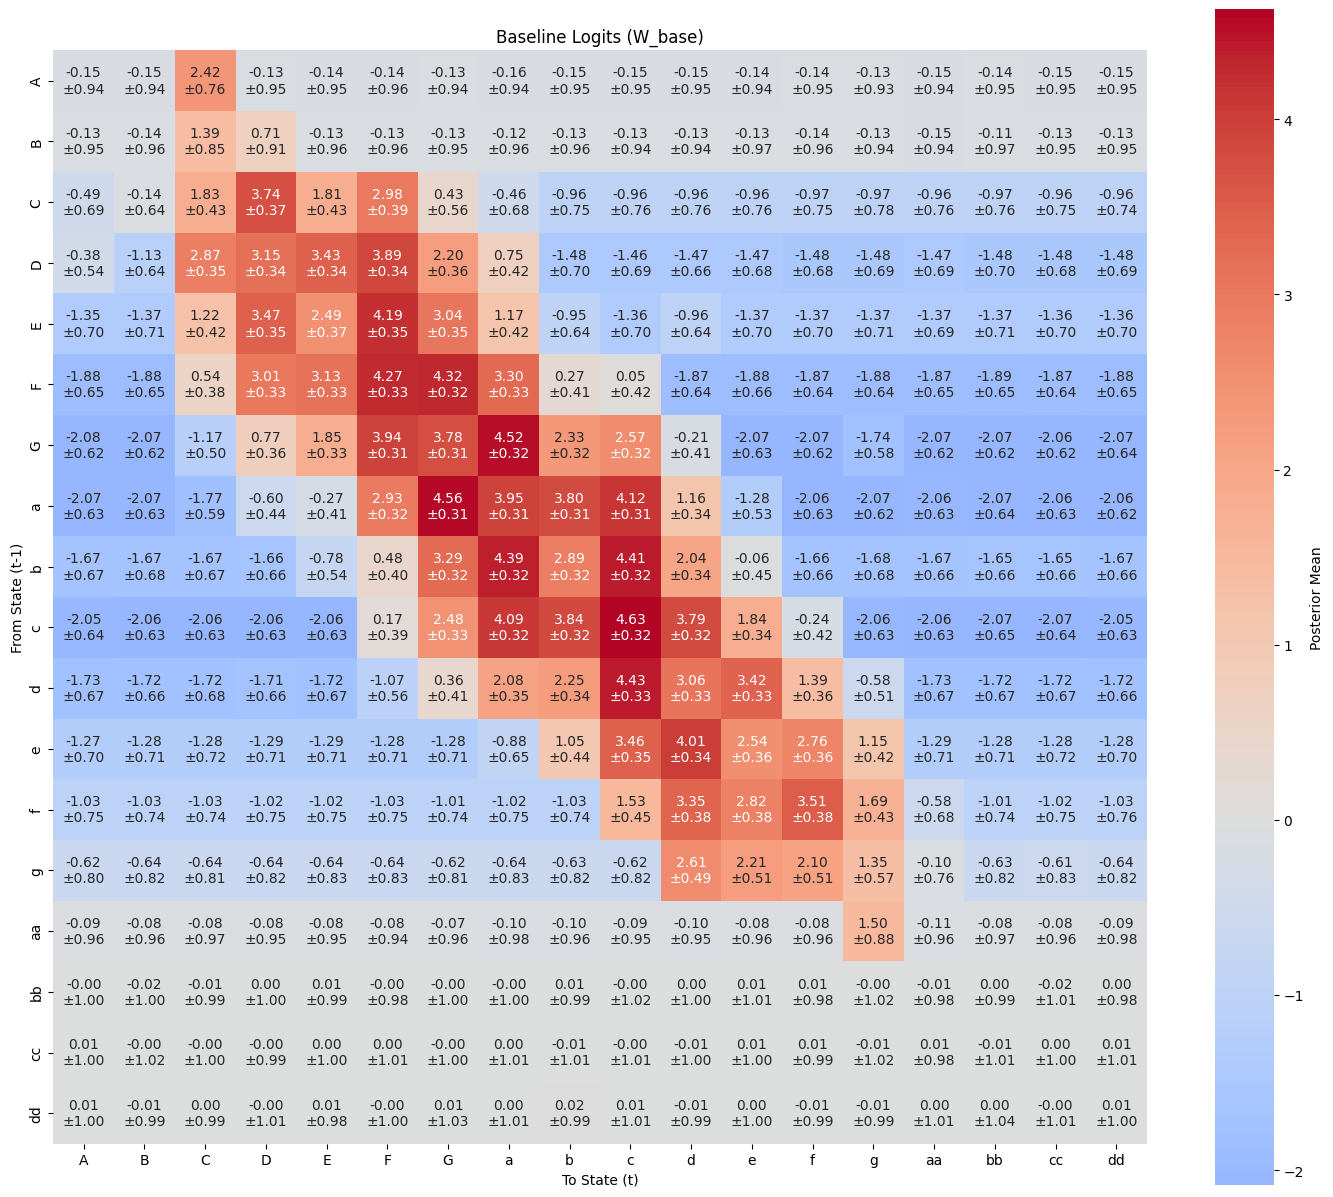





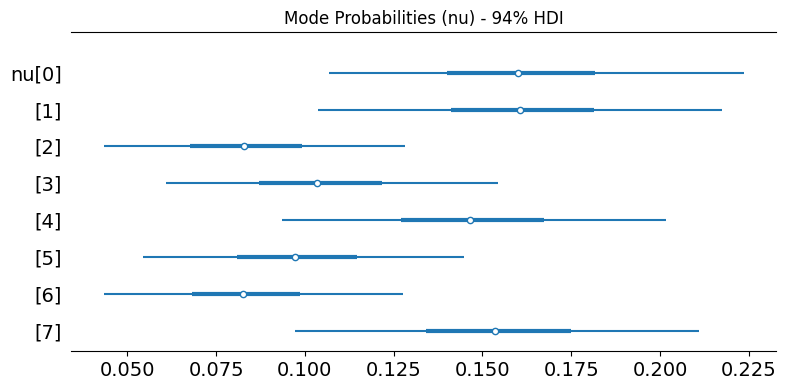

In [23]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


def _generate_pitch_labels(v_size):
    base_notes = ["A", "B", "C", "D", "E", "F", "G"]
    labels = []
    for i in range(v_size):
        octave = i // 7
        note = base_notes[i % 7]
        if octave == 0:
            labels.append(note)
        else:
            labels.append(note.lower() * octave)
    return labels


def _extract_summary_stats(idata, var_name):
    posterior = idata.posterior[var_name]
    mean_vals = posterior.mean(dim=["chain", "draw"]).values
    std_vals = posterior.std(dim=["chain", "draw"]).values
    return mean_vals, std_vals


def _create_annotation_matrix(mean_vals, std_vals):
    annot = np.empty_like(mean_vals, dtype=object)
    for i in range(mean_vals.shape[0]):
        for j in range(mean_vals.shape[1]):
            annot[i, j] = f"{mean_vals[i, j]:.2f}\n±{std_vals[i, j]:.2f}"
    return annot


def _calculate_figsize(v_size, num_plots=1):
    base_size = max(8.0, v_size * 0.8)
    return (base_size * num_plots, base_size * 0.85)


def _draw_annotated_heatmap(mean_vals, std_vals, ax, title, cmap="viridis", center=None, v_labels=None):
    annot_matrix = _create_annotation_matrix(mean_vals, std_vals)
    
    sns.heatmap(
        mean_vals,
        annot=annot_matrix,
        fmt="",
        cmap=cmap,
        ax=ax,
        center=center,
        xticklabels=v_labels if v_labels is not None else "auto",
        yticklabels=v_labels if v_labels is not None else "auto",
        cbar_kws={"label": "Posterior Mean"},
        square=True,
        annot_kws={"size": 10}
    )
    ax.set_title(title)
    ax.set_xlabel("To State (t)")
    ax.set_ylabel("From State (t-1)")


def plot_baseline_logits(idata, v_size):
    v_labels = _generate_pitch_labels(v_size)
    mean_vals, std_vals = _extract_summary_stats(idata, "W_base")
    
    fig, ax = plt.subplots(figsize=_calculate_figsize(v_size))
    _draw_annotated_heatmap(
        mean_vals, 
        std_vals, 
        ax, 
        title="Baseline Logits (W_base)", 
        cmap="coolwarm", 
        center=0,
        v_labels=v_labels
    )
    plt.savefig("visual/model4_logit_baseline_logits.png")
    plt.tight_layout()
    return fig


def plot_mode_offsets(idata, v_size, m_labels=None):
    v_labels = _generate_pitch_labels(v_size)
    mean_vals, std_vals = _extract_summary_stats(idata, "W_mode_offset")
    M = mean_vals.shape[0]
    
    if m_labels is None:
        m_labels = [f"Mode {m}" for m in range(M)]
        
    fig, axes = plt.subplots(1, M, figsize=_calculate_figsize(v_size, M))
    if M == 1:
        axes = [axes]
        
    for m, ax in enumerate(axes):
        _draw_annotated_heatmap(
            mean_vals[m], 
            std_vals[m], 
            ax, 
            title=f"Logit Offsets: {m_labels[m]}", 
            cmap="coolwarm", 
            center=0,
            v_labels=v_labels
        )
    
    plt.savefig("visual/model4_logit_mode_offsets.png")
    plt.tight_layout()
    return fig


def plot_transition_matrices(idata, v_size, m_labels=None):
    v_labels = _generate_pitch_labels(v_size)
    mean_vals, std_vals = _extract_summary_stats(idata, "A")
    M = mean_vals.shape[0]
    
    if m_labels is None:
        m_labels = [f"Mode {m}" for m in range(M)]
        
    fig, axes = plt.subplots(1, M, figsize=_calculate_figsize(v_size, M))
    if M == 1:
        axes = [axes]
        
    for m, ax in enumerate(axes):
        _draw_annotated_heatmap(
            mean_vals[m], 
            std_vals[m], 
            ax, 
            title=f"Transition Probabilities: {m_labels[m]}", 
            cmap="Blues", 
            v_labels=v_labels
        )
        
    plt.tight_layout()
    plt.savefig("visual/model4_logit_trans_matr.png")
    return fig


def plot_mode_probabilities(idata):
    fig, ax = plt.subplots(figsize=(8, 4))
    az.plot_forest(
        idata, 
        var_names=["nu"], 
        combined=True, 
        hdi_prob=0.94, 
        ax=ax
    )
    ax.set_title("Mode Probabilities (nu) - 94% HDI")
    plt.tight_layout()
    plt.savefig("visual/model4_logit_mode_prob.png")
    return fig


def plot_all_posteriors(idata, v_size, m_labels=None):
    figs = {
        "baseline_logits": plot_baseline_logits(idata, v_size),
        "mode_offsets": plot_mode_offsets(idata, v_size, m_labels),
        "transition_matrices": plot_transition_matrices(idata, v_size, m_labels),
        "mode_probabilities": plot_mode_probabilities(idata)
    }
    return figs
plot_all_posteriors(trace, m3.V)